In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import scipy
from scipy.optimize import minimize_scalar
from scipy.optimize import minimize
np.set_printoptions(legacy='1.21')

In [2]:
#Function defined in previous class
def portfolio_volatility(weights, std_devs, corr_matrix):
    w = np.asarray(weights)
    s = np.asarray(std_devs)
    C = np.asarray(corr_matrix)
    D = np.diag(s)
    Sigma = D @ C @ D
    var_p = w.T @ Sigma @ w
    vol_p = np.sqrt(var_p)
    return vol_p

# Portfolio expected return. Vector of weights and return 
#must have the same size
def expret(weights,returns):
    w = np.asarray(weights)
    r = np.asarray(returns)
    return w.T@r

#Compute optimal portfolio weights maximizing expected return
#subject to volatility constraint and 0 <= w_i <= 1, sum(w)=1.
#Parameters:
# r : array-like, shape (n,1)          Expected returns of assets.
# Sigma : array-like, shape (n, n)     Covariance matrix of asset returns.
#sigma_max : float                     Maximum allowed portfolio volatility.
      
def optimal_portfolio(r, Sigma, sigma_max):
    mu = np.array(r)
    Sigma = np.array(Sigma)
    n = len(mu)
    # Objective function: negative expected return (for minimization)
    def objective(w):
        return -mu @ w    
    # Constraint: volatility <= sigma_max
    def volatility_constraint(w):
        return sigma_max - np.sqrt(w @ Sigma @ w)  
    # Constraint: sum of weights = 1
    def weight_sum_constraint(w):
        return np.sum(w) - 1.0
    # Initial guess: equally weighted portfolio
    w0 = np.ones(n) / n
    # Bounds: 0 <= w_i <= 1
    bounds = [(0.0, 1.0) for _ in range(n)]
    # Define constraints dictionary for optimizer
    constraints = [
        {'type': 'eq', 'fun': weight_sum_constraint},
        {'type': 'ineq', 'fun': volatility_constraint}
    ]
    # Optimization
    result = minimize(objective, w0, bounds=bounds, constraints=constraints)
    if not result.success:
        raise ValueError("Optimization failed:", result.message)
    return result.x


#Minimizing volatility for a given target on expected returns
#No short sales.   0 <= w_i <= 1 and sum(w)=1.
def min_volatility_portfolio(r, Sigma, target_return):
    mu = np.array(r)
    Sigma = np.array(Sigma)
    n = len(mu)
    # Objective: minimize portfolio volatility (standard deviation)
    def objective(w):
        return np.sqrt(w @ Sigma @ w)
    # Constraint: expected return >= target_return
    def return_constraint(w):
        return mu @ w - target_return
    # Constraint: sum of weights = 1
    def weight_sum_constraint(w):
        return np.sum(w) - 1.0
    # Initial guess and bounds
    w0 = np.ones(n) / n
    bounds = [(0.0, 1.0) for _ in range(n)]    
    constraints = [
        {'type': 'eq', 'fun': weight_sum_constraint},
        {'type': 'ineq', 'fun': return_constraint}
    ]
    result = minimize(objective, w0, bounds=bounds, constraints=constraints)
    if not result.success:
        raise ValueError("Optimization failed:", result.message)    
    return result.x

# Constructing portfolios for different target returns
target_returns = np.linspace(0.08, 0.15, 30)

# Example
r = np.array([0.08, 0.12, 0.15])  # Expected returns
S = np.array([                    # Covariance matrix
    [0.04, 0.01, 0.02],
    [0.01, 0.09, 0.03],
    [0.02, 0.03, 0.16]
])
#min_volatility_portfolio(r, S, 0.13)
# Store results
frontier_vols = []
frontier_rets = []
for r_target in target_returns:
    w = min_volatility_portfolio(r, S, r_target)
    port_ret = r @ w
    port_vol = np.sqrt(w @ S @ w)
    frontier_rets.append(port_ret)
    frontier_vols.append(port_vol)

# ===== Plot Efficient Frontier =====
#plt.figure(figsize=(8,5))
#plt.plot(frontier_vols, frontier_rets, 'b-', lw=2)
#plt.title("Efficient Frontier (No Short Selling)")
#plt.xlabel("Portfolio Volatility (Standard Deviation)")
#plt.ylabel("Expected Return")
#plt.grid(True)
#plt.show()

In [3]:
#Compute the Global Minimum Variance (GMV) portfolio.
#Short selling allowed.

def global_min_variance_portfolio(Sigma):
    # Get the number of assets (n) from the row dimension of Sigma
    n = Sigma.shape[0]
    # Compute the inverse of the covariance matrix (Sigma^-1)
    Sigma_inv = np.linalg.inv(Sigma)
    # Create a vector of ones of length n
    ones = np.ones(n)  
    # Calculate unnormalized weights via matrix multiplication (Sigma^-1 * 1)
    w_gmv = Sigma_inv @ ones
    # Normalize weights so their sum equals 1
    w_gmv /= np.sum(w_gmv)
    return w_gmv

In [4]:
#Compute the minimum-variance portfolio achieving a target return.
#Short selling is allowed.
def min_var_portfolio(r, Sigma, target_return):
    # Get the total number of assets (n) from the length of expected returns
    n = len(r)
    # Convert expected returns list/array into a 1D NumPy vector (mu)
    mu = np.array(r)
    # Convert covariance input into a 2D NumPy array (Sigma)
    Sigma = np.array(Sigma)
    # Compute the matrix inverse of the covariance matrix (Sigma^-1)
    Sigma_inv = np.linalg.inv(Sigma)
    # Calculate scalar constant A: mu^T * Sigma^-1 * mu
    A = mu @ Sigma_inv @ mu
    # Calculate scalar constant B: mu^T * Sigma^-1 * 1
    B = mu @ Sigma_inv @ np.ones(n)
    # Calculate scalar constant C: 1^T * Sigma^-1 * 1
    C = np.ones(n) @ Sigma_inv @ np.ones(n)
    # Calculate determinant constant D = A*C - B^2 (Efficiency parabola determinant)
    D = A * C - B**2
    # Compute Lagrange multiplier 1 for the target return constraint
    lambda1 = (C * target_return - B) / D
    # Compute Lagrange multiplier 2 for the weight sum constraint (sum w_i = 1)
    lambda2 = (A - B * target_return) / D
    # Compute optimal portfolio weights vector w = Sigma^-1 * (lambda1 * mu + lambda2 * 1)
    w = Sigma_inv @ (lambda1 * mu + lambda2 * np.ones(n))
    return w

In [5]:
#Example 
min_var_portfolio(r, S, 0.14)

array([-0.08756567,  0.53765324,  0.54991243])

In [6]:
#Compute the tangency (maximum Sharpe ratio) portfolio.
#The Sharpe ratio for a portfolio p is (r_p-r_f)/sigma_p
#Short selling is allowed.

def tangency_portfolio(r, Sigma, rf):
    mu = np.array(r)
    Sigma = np.array(Sigma)
    excess_returns = mu - rf
    Sigma_inv = np.linalg.inv(Sigma)
    w_tan = Sigma_inv @ excess_returns
    w_tan /= np.sum(w_tan)  # Normalize to sum to 1
    return w_tan

In [7]:
rfree=0.03
weff=tangency_portfolio(r,S,rfree)
weff

array([0.39320388, 0.3592233 , 0.24757282])

In [8]:
#Compute the maximum Sharpe ratio portfolio when short selling is not allowed

def max_sharpe_ratio(returns, cov_matrix, risk_free_rate):
    n = len(returns)
    # Objective function: minimize the negative Sharpe ratio
    def neg_sharpe(weights):
        port_return = np.dot(weights, returns)
        port_vol = np.sqrt(np.dot(weights.T, np.dot(cov_matrix, weights)))
        sharpe = (port_return - risk_free_rate) / port_vol
        return -sharpe  # negative for minimization    
    # Constraints: sum of weights = 1
    constraints = {'type': 'eq', 'fun': lambda w: np.sum(w) - 1}
    
    # Bounds: all weights between 0 and 1
    bounds = tuple((0.0, 1.0) for _ in range(n))
    
    # Initial guess: equal weights
    w0 = np.ones(n) / n
    
    result = minimize(neg_sharpe, w0, bounds=bounds, constraints=constraints)
    
    if not result.success:
        raise ValueError("Optimization failed: " + result.message)   
    opt_weights = result.x
    max_sharpe = -result.fun
    return opt_weights, max_sharpe

In [9]:
#Example
n_assets = 4
exp_returns = np.array([0.12, 0.10, 0.15, 0.09])
cov_matrix = np.array([
    [0.04, 0.006, 0.012, 0.002],
    [0.006, 0.03, 0.004, 0.008],
    [0.012, 0.004, 0.05, 0.010],
    [0.002, 0.008, 0.010, 0.025]
    ])
rf_rate = 0.03

weights, sharpe = max_sharpe_ratio(exp_returns, cov_matrix, rf_rate)
print("Optimal Weights:", np.round(weights, 4))
print("Maximum Sharpe Ratio:", round(sharpe, 4))

Optimal Weights: [0.2505 0.262  0.2948 0.1927]
Maximum Sharpe Ratio: 0.7133


In [10]:
max_sharpe_ratio(exp_returns, cov_matrix, rf_rate)[1]

0.7133278763973118

In [11]:
# ===== Compute portfolios =====
# Global Minimum Variance portfolio
Sigma=cov_matrix
mu=exp_returns
w_gmv = global_min_variance_portfolio(Sigma)
r_gmv = mu @ w_gmv
sigma_gmv = np.sqrt(w_gmv @ Sigma @ w_gmv)
w_gmv

array([0.23652528, 0.2775977 , 0.10969624, 0.37618077])

In [12]:
# Efficient frontier
target_returns = np.linspace(r_gmv, 0.18, 50)
frontier_vols, frontier_rets = [], []
for r_target in target_returns:
    w = min_var_portfolio(mu, Sigma, r_target)
    port_ret = mu @ w
    port_vol = np.sqrt(w @ Sigma @ w)
    frontier_rets.append(port_ret)
    frontier_vols.append(port_vol)

In [13]:
# Tangency portfolio
risk_free_rate=0.05
w_tan = tangency_portfolio(mu, Sigma, risk_free_rate)

#return at the tangency portfolio
r_tan = mu @ w_tan

#volatility at the tangency portfolio
sigma_tan = np.sqrt(w_tan @ Sigma @ w_tan)

#Slope of the tangent line. The intercept is the 
#risk-free rate

sharpe_tan = (r_tan - risk_free_rate) / sigma_tan

In [14]:
w_tan

array([0.2562235 , 0.25633013, 0.35998261, 0.12746377])

In [15]:
wa=max_sharpe_ratio(mu, Sigma, risk_free_rate)
wa

(array([0.25596014, 0.25650982, 0.35917674, 0.12835331]), 0.5544282909709626)

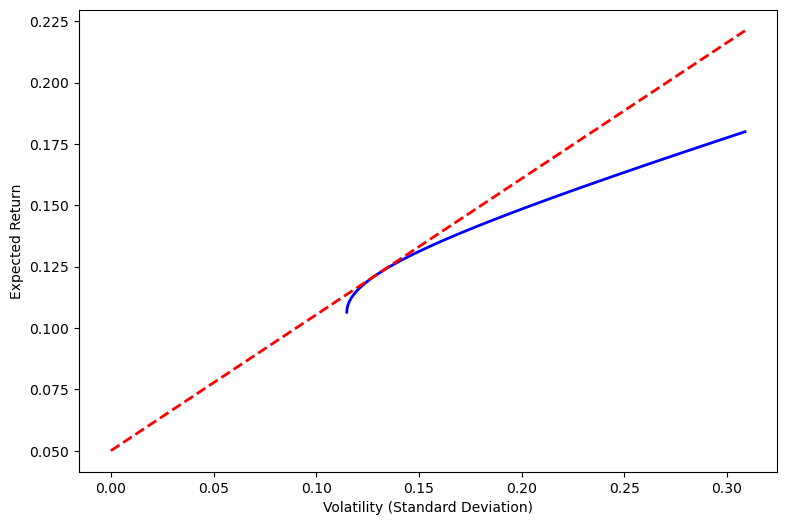

In [16]:
# Capital Market Line (CML)
sigma_cml = np.linspace(0, max(frontier_vols), 100)
r_cml = risk_free_rate + sharpe_tan * sigma_cml


# ===== Plot =====
plt.figure(figsize=(9,6))
plt.plot(frontier_vols, frontier_rets, 'b-', lw=2, label='Efficient Frontier')
plt.plot(sigma_cml, r_cml, 'r--', lw=2, label='Capital Market Line (CML)')
#plt.scatter(sigma_gmv, r_gmv, color='purple', s=80, label='Global Min Variance Portfolio')
#plt.scatter(sigma_tan, r_tan, color='green', s=80, label='Tangency Portfolio')
#plt.scatter(np.sqrt(np.diag(Sigma)), mu, color='black', label='Individual Assets')
#plt.title("Efficient Frontier, Tangency, GMV, and CML (Short Selling Allowed)")
plt.xlabel("Volatility (Standard Deviation)")
plt.ylabel("Expected Return")
#plt.legend()
#plt.grid(True)
plt.show()


In [17]:
#===== Print summary =====
print("Global Minimum Variance Portfolio:")
print("Weights:", np.round(w_gmv, 3))
print("Expected return:", round(r_gmv, 4))
print("Volatility:", round(sigma_gmv, 4))
print("Tangency Portfolio:")
print("Weights:", np.round(w_tan, 3))
print("Expected return:", round(r_tan, 4))
print("Volatility:", round(sigma_tan, 4))
print("Sharpe ratio:", round(sharpe_tan, 4))

Global Minimum Variance Portfolio:
Weights: [0.237 0.278 0.11  0.376]
Expected return: 0.1065
Volatility: 0.1149
Tangency Portfolio:
Weights: [0.256 0.256 0.36  0.127]
Expected return: 0.1218
Volatility: 0.1296
Sharpe ratio: 0.5544


In [18]:
russell = pd.read_csv('russell.csv')
nasdaq =  pd.read_csv('nasdaq.csv')
DowJones= pd.read_csv('Dow Jones.csv')

In [19]:
rusreturn    =russell['Return']
nasdaqreturn =nasdaq['Return']
DJreturn     =DowJones['Return']
print(len(rusreturn))
rusreturn=rusreturn[0:465]
nasdaqreturn=nasdaqreturn[0:465]
DJreturn=DJreturn[0:465]

467


In [20]:
Sindices=np.cov([rusreturn,nasdaqreturn,DJreturn])*252
Sindices

array([[0.04860014, 0.03661085, 0.02672369],
       [0.03661085, 0.04738159, 0.02466872],
       [0.02672369, 0.02466872, 0.02081422]])

In [21]:
np.sqrt(Sindices)

array([[0.2204544 , 0.19133963, 0.16347383],
       [0.19133963, 0.21767312, 0.1570628 ],
       [0.16347383, 0.1570628 , 0.14427134]])

In [22]:
Scorr=np.corrcoef([rusreturn,nasdaqreturn,DJreturn])
Scorr[0,1]*np.sqrt(Sindices[0,0])*np.sqrt(Sindices[1,1])

0.03661085239024862

In [23]:
Scorr

array([[1.        , 0.76293276, 0.84022897],
       [0.76293276, 1.        , 0.78552828],
       [0.84022897, 0.78552828, 1.        ]])

In [24]:
np.round(Scorr,3)

array([[1.   , 0.763, 0.84 ],
       [0.763, 1.   , 0.786],
       [0.84 , 0.786, 1.   ]])

In [25]:
Sindices_inv=np.linalg.inv(Sindices)

In [26]:
rindices=[np.mean(rusreturn)*252,np.mean(nasdaqreturn)*252,np.mean(DJreturn)*252]
rindices

[0.14662657068387097, 0.28248030828387094, 0.1379941379690323]

In [27]:
rf=0.05
weff=Sindices_inv @ (rindices-rf*np.ones(3))
weff

array([-3.95819337,  8.14225608, -0.34050673])

In [28]:
#Efficient frontier for the 3 indexes
# Range of target returns
target_returns = np.linspace(min(rindices), max(rindices), 50)

# Store results
indices_vols = []
indices_rets = []

for r_target in target_returns:
    w = min_volatility_portfolio(rindices, Sindices, r_target)
    port_ret = rindices @ w
    port_vol = np.sqrt(w @ Sindices @ w)
    indices_rets.append(port_ret)
    indices_vols.append(port_vol)

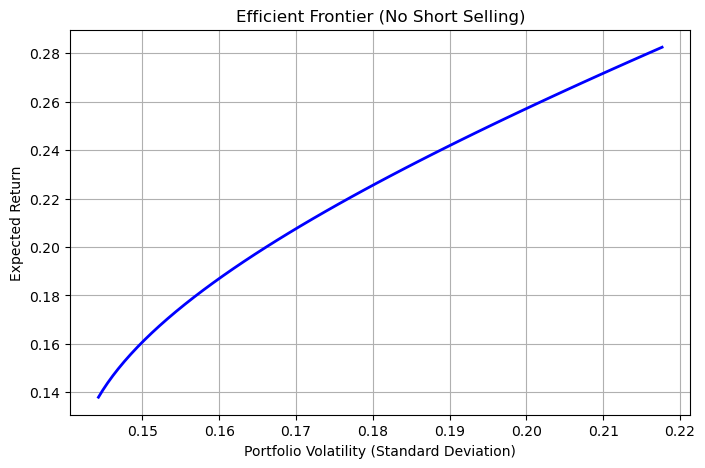

In [29]:
# ===== Plot Efficient Frontier =====
plt.figure(figsize=(8,5))
plt.plot(indices_vols, indices_rets, 'b-', lw=2)
plt.title("Efficient Frontier (No Short Selling)")
plt.xlabel("Portfolio Volatility (Standard Deviation)")
plt.ylabel("Expected Return")
plt.grid(True)
plt.show()

In [30]:
#Compute the Global Minimum Variance (GMV) portfolio using the three indices.
#Short selling allowed.

wmin=global_min_variance_portfolio(Sindices)
wmin

array([-0.33314731, -0.09782092,  1.43096824])

In [31]:
wmin @ rindices

0.12098449571741225

In [32]:
#Compute the tangency (maximum Sharpe ratio) portfolio. No short sale on stocks
rfree=0.02
weff=max_sharpe_ratio(rindices, Sindices, rfree)[0]
#weff=tangency_portfolio(rindices, Sindices, rfree)
weff

array([0.00000000e+00, 1.00000000e+00, 1.66533454e-16])

In [33]:
r_eff = rindices @ weff
r_eff

0.28248030828387094

In [34]:
sigma_eff = np.sqrt(weff @ Sindices @ weff)
sigma_eff

0.217673117683341

In [35]:
sharpe_eff = (r_eff - rfree) / sigma_eff
sharpe_eff

1.2058462297843917

In [36]:
# Capital Market Line (CML)
sigma_cml = np.linspace(0, 2*max(indices_vols), 100)
r_cml = rfree + sharpe_eff * sigma_cml

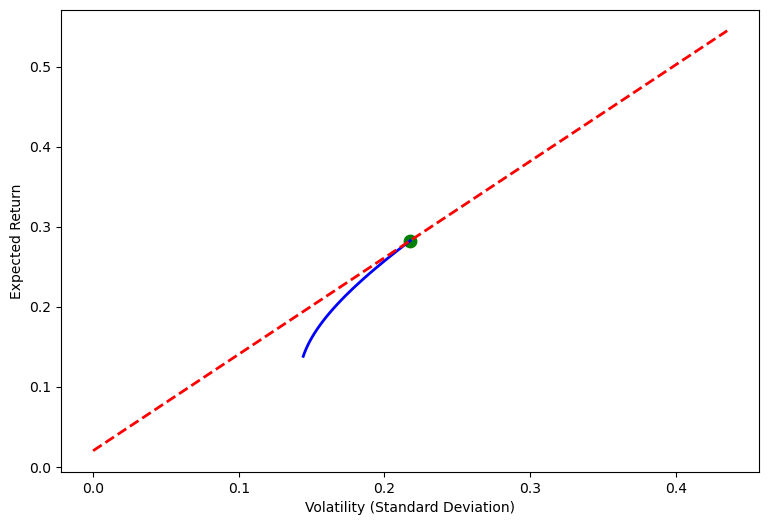

In [37]:
# ===== Plot =====
plt.figure(figsize=(9,6))
plt.plot(indices_vols, indices_rets, 'b-', lw=2, label='Efficient Frontier')
plt.plot(sigma_cml, r_cml, 'r--', lw=2, label='Capital Market Line (CML)')
#plt.scatter(sigma_gmv, r_gmv, color='purple', s=80, label='Global Min Variance Portfolio')
plt.scatter(sigma_eff, r_eff, color='green', s=80, label='Tangency Portfolio')
#plt.scatter(np.sqrt(np.diag(Sigma)), mu, color='black', label='Individual Assets')
#plt.title("Efficient Frontier, Tangency, GMV, and CML (Short Selling Allowed)")
plt.xlabel("Volatility (Standard Deviation)")
plt.ylabel("Expected Return")
#plt.legend()
#plt.grid(True)
plt.show()